# Lab01 - sprint 2
## Генератор и реальные оценки
### Description

Для каждой крепости из test строим распределение оценок по соседям из train, k = 720.
Реальные оценки test при построении распределений не используем.
Генерируем по одной оценке на каждое тестовое вино и повторяем опыт 1000 раз, seed = 2026.
Так сравниваем одинаковый состав по крепости и одинаковые размеры выборок.

Test уже использовался для оценки регрессии. Это дополнительная диагностика фиксированного генератора,
а не новый независимый эксперимент. Параметры по результатам не меняем.


In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib
# Backend задаёт Jupyter.
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'pyproject.toml').is_file())
sys.path.insert(0,str(ROOT/'src'))
from wine_stats.data import load_wines
from wine_stats.split import split_wines
from wine_stats.generator import quality_distribution, inverse_cdf
meta=json.loads((ROOT/'data/processed/alcohol_quality_split.json').read_text())
for name,info in meta['files'].items():
    assert hashlib.sha256((ROOT/'data/raw'/name).read_bytes()).hexdigest()==info['sha256']
df=load_wines(ROOT/'data/raw')
manifest=pd.read_csv(ROOT/'data/processed/alcohol_quality_split.csv')
pd.testing.assert_frame_equal(manifest,split_wines(df,seed=42))
assert manifest.groupby('group_id')['split'].nunique().max()==1
train=df.loc[manifest['split'].eq('train')]
test_all=df.loc[manifest['split'].eq('test')]
supported=test_all.alcohol.between(train.alcohol.min(),train.alcohol.max())
test=test_all.loc[supported]
print(f'Test: {len(test_all)}; в диапазоне train: {len(test)}; вне диапазона: {(~supported).sum()}')
K=720
REPEATS=1000
rng=np.random.default_rng(2026)
scores=np.arange(11)
probabilities=np.zeros((len(test),len(scores)))
for i,x in enumerate(test.alcohol):
    values,p=quality_distribution(train.alcohol,train.quality,x,k=K)
    probabilities[i,values]=p
assert np.allclose(probabilities.sum(axis=1),1)
generated=np.column_stack([inverse_cdf(scores,p,rng.random(REPEATS)) for p in probabilities])
observed=test.quality.to_numpy()

from wine_stats.plotting import use_style
use_style()

Test: 1302; в диапазоне train: 1302; вне диапазона: 0


### tests - метрики и частоты

«Модель» - точные метрики смеси распределений для тестовых крепостей.
«Генерация» - среднее метрики по 1000 опытам.
Диапазон 2,5-97,5% показывает разброс симуляций при фиксированной модели, а не доверительный интервал истинной характеристики вин.
Дисперсии считаем со знаменателем n; квантили - по обратной эмпирической функции распределения.


In [2]:
def statistics(a):
    return np.column_stack([a.mean(axis=1),a.var(axis=1),
        *np.quantile(a,[.25,.5,.75],axis=1,method='inverted_cdf')])
sim=statistics(generated)
real=statistics(observed[None,:])[0]
mixture=probabilities.mean(axis=0)
mu=scores@mixture
model=np.r_[mu,((scores-mu)**2)@mixture,
            scores[np.searchsorted(np.cumsum(mixture),[.25,.5,.75])]]
comparison=pd.DataFrame({'metric':['mean','variance','q25','median','q75'],
    'real':real,'model':model,'generated_mean':sim.mean(axis=0),
    'simulation_q025':np.quantile(sim,.025,axis=0),
    'simulation_q975':np.quantile(sim,.975,axis=0)})
display(comparison.round(4))
freq=np.array([(generated==q).mean(axis=1) for q in scores]).T
real_freq=np.array([(observed==q).mean() for q in scores])
frequencies=pd.DataFrame({'quality':scores,'real':real_freq,'model':mixture,
    'generated_mean':freq.mean(axis=0),'simulation_q025':np.quantile(freq,.025,axis=0),
    'simulation_q975':np.quantile(freq,.975,axis=0)})
display(frequencies.round(4))
tv=.5*np.abs(real_freq-mixture).sum()
print(f'Расстояние полной вариации реальность/модель: {tv:.4f}')
tables=ROOT/'reports/tables'
comparison.to_csv(tables/'generator_real_metrics.csv',index=False)
frequencies.to_csv(tables/'generator_real_frequencies.csv',index=False)


,metric,real,model,generated_mean,simulation_q025,simulation_q975
0,mean,5.8295,5.7816,5.7810,5.7381,5.8233
1,variance,0.7313,0.7383,0.7383,0.6836,0.7949
2,q25,5.0000,5.0000,5.0000,5.0000,5.0000
3,median,6.0000,6.0000,6.0000,6.0000,6.0000
4,q75,6.0000,6.0000,6.0000,6.0000,6.0000


,quality,real,model,generated_mean,simulation_q025,simulation_q975
0,0,0.0000,0.0000,0.0000,0.0000,0.0000
1,1,0.0000,0.0000,0.0000,0.0000,0.0000
2,2,0.0000,0.0000,0.0000,0.0000,0.0000
3,3,0.0031,0.0046,0.0046,0.0015,0.0084
4,4,0.0338,0.0331,0.0332,0.0246,0.0438
5,5,0.3195,0.3462,0.3464,0.3226,0.3710
6,6,0.4439,0.4363,0.4361,0.4109,0.4639
7,7,0.1736,0.1525,0.1523,0.1344,0.1713
8,8,0.0261,0.0264,0.0264,0.0177,0.0353
9,9,0.0000,0.0008,0.0008,0.0000,0.0031


Расстояние полной вариации реальность/модель: 0.0294


### Диагностика по крепости

Общее совпадение может скрывать ошибки в отдельных группах. Сравним средние в диапазонах
до 10%, 10-11%, 11-12% и от 12% спирта. Верхняя граница каждого интервала не включается.


,alcohol_bin,n,real_mean,model_mean,simulation_q025,simulation_q975
0,"[-inf, 10.0)",546,5.5110,5.4172,5.3571,5.4707
1,"[10.0, 11.0)",337,5.7804,5.7531,5.6647,5.8338
2,"[11.0, 12.0)",232,6.1164,6.1054,5.9956,6.2155
3,"[12.0, inf)",187,6.4920,6.4949,6.3797,6.6043


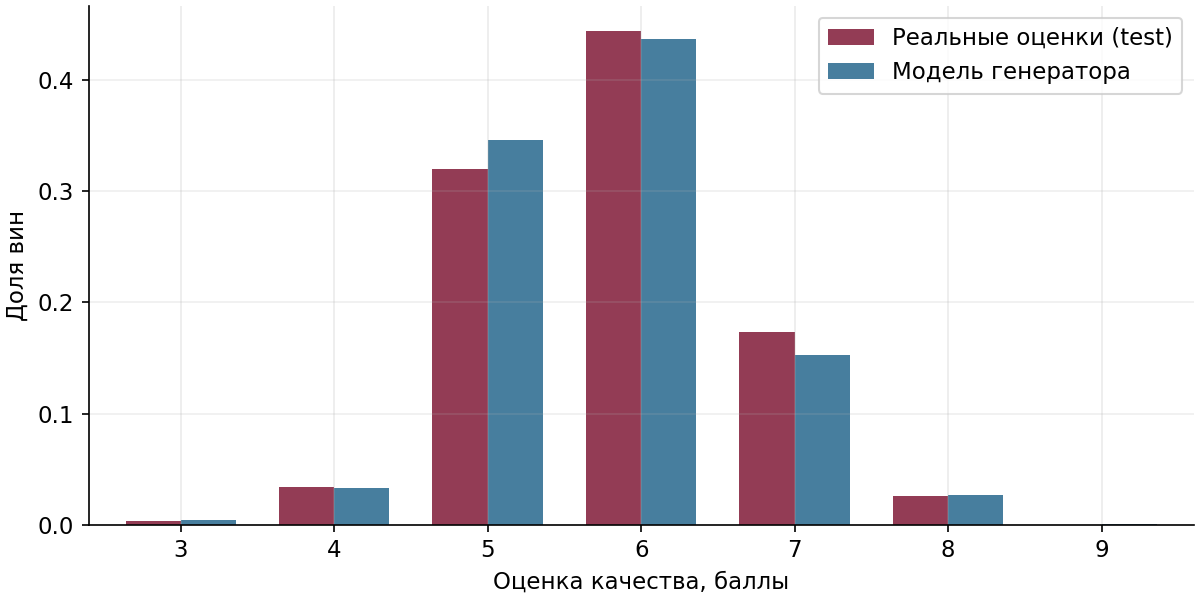

In [3]:
bins=pd.cut(test.alcohol,[-np.inf,10,11,12,np.inf],right=False)
groups=[]
for label in bins.cat.categories:
    mask=(bins==label).to_numpy()
    if not mask.any():continue
    group_p=probabilities[mask].mean(axis=0)
    means=generated[:,mask].mean(axis=1)
    groups.append({'alcohol_bin':str(label),'n':int(mask.sum()),
        'real_mean':observed[mask].mean(),'model_mean':group_p@scores,
        'simulation_q025':np.quantile(means,.025),'simulation_q975':np.quantile(means,.975)})
groups=pd.DataFrame(groups)
display(groups.round(4))
groups.to_csv(tables/'generator_real_by_alcohol.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
ax.bar(scores-.18,real_freq,width=.36,label='Реальные оценки (test)',color='#933c55')
ax.bar(scores+.18,mixture,width=.36,label='Модель генератора',color='#477e9e')
ax.set(xlabel='Оценка качества, баллы',ylabel='Доля вин',xticks=scores,xlim=(2.4,9.6))
ax.legend();ax.grid(axis='y',alpha=.2)
path=ROOT/'reports/figures/generator_real_frequencies.png'
fig.savefig(path,dpi=150);plt.close(fig)
display(Image(filename=str(path)))


### resume

Проверены все 1302 тестовых вина. Средняя реальная оценка - 5,829 балла,
средняя по 1000 генерациям - 5,781: генератор занижает её примерно на 0,048 балла.
Дисперсии близки: 0,731 у реальных данных и 0,738 в генерациях.
Квартили совпали: 5, 6 и 6 баллов.

Расстояние полной вариации между реальными частотами и моделью - 0,0294.
Это небольшое общее расхождение частот, но оно не доказывает совпадение условных распределений.
Главная заметная ошибка - у вин крепостью ниже 10%:
реальное среднее 5,511, модельное 5,417 (разница −0,094 балла).

Реальное общее среднее немного выше диапазона 2,5-97,5% симуляций.
Поэтому утверждать полное согласие с данными нельзя.
Генератор воспроизводит общий разброс, но имеет смещение для части вин.

Диапазоны симуляций отражают только случайность генерации при фиксированных вероятностях.
Они не учитывают неопределённость обучения и зависимость повторяющихся наблюдений.
Формальный тест равенства распределений здесь не проводился.
Для дисперсии сравнивается дисперсия смеси с эмпирической дисперсией конечной выборки;
их математические ожидания могут немного различаться.

## Lab resume
### cat_mark_table

| cat_id | notebook_link | coeff | comment |
|---|---|---|---|
| - | [Сравнение](04_generator_comparison.ipynb) | - | Метрики, частоты и повторные генерации на крепостях test. |
